# Análise Exploratória - ESA Anomaly Dataset

Este notebook faz parte de uma Iniciação Científica que estuda como avaliar a **confiabilidade de alertas em telemetria espacial**.

## Contexto

Satélites geram continuamente séries temporais chamadas de **telemetria** — medidas de temperatura, tensão, corrente e outros parâmetros dos seus subsistemas. Sistemas de monitoramento observam esses dados e emitem **alertas** quando detectam  comportamentos fora do padrão.

O problema central é que **um alerta não significa necessariamente uma falha real**.  O mesmo comportamento atípico pode ser:

- 🔴 Uma **anomalia real** — algo efetivamente errado no satélite
- 🟡 Um **evento nominal raro** — uma operação planejada, incomum mas esperada  (ex: uma manobra, uma calibração)
- ⚪ **Ruído ou problema de qualidade dos dados**

Esta análise exploratória vai nos ajudar a **entender a estrutura dos dados disponíveis** antes de construir qualquer detector ou avaliador de alertas.

In [47]:
# import das bibliotecas e carregamento dos dataset
import pickle
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("../../data/ESA/ESA-Mission1")

def load_zip_pickle(path: Path) -> pd.DataFrame:
    """Carrega um DataFrame pickled dentro de um ZIP."""
    with zipfile.ZipFile(path) as z:
        name = z.namelist()[0]
        return pickle.loads(z.read(name))

## O que vamos fazer aqui

Este notebook segue uma progressão natural:

1. **Carregar e inspecionar os metadados** (CSVs) — entender o que existe antes de abrir os arquivos grandes
2. **Carregar as séries temporais** dos canais 41 - 46 — ver como os dados reais se parecem
3. **Visualizar os canais** — identificar padrões, anomalias e eventos nominais raros visualmente
4. **Carregar e visualizar telecomandos** — entender quando e com que frequência comandos foram enviados
5. **Explorar a possibilidade de combinação** — verificar se faz sentido cruzar séries de 
   telemetria com o histórico de telecomandos (join temporal)

## Escopo desta etapa: Mission1

Nesta primeira análise exploratória, vamos focar na **Mission1** do ESA-ADB. A análise equivalente da Mission2 fica para uma etapa posterior, depois de compreendermos e documentarmos este recorte.

### Recorte atual

- **Telemetria:** canais 41–46, que são os canais disponíveis neste subconjunto local.
- **Eventos:** rótulos associados aos canais 41–46, cruzados com `anomaly_types.csv`. As contagens de eventos desta análise serão de **IDs únicos presentes no recorte**, não do total da Mission1.
- **Telecomandos:** catálogo da Mission1 e históricos disponíveis em `telecommands/`, usados para caracterização e análise de proximidade temporal. Uma associação temporal não demonstra causalidade.

### O que esta EDA deve produzir

Vamos caracterizar os eventos, os canais, a amostragem, a qualidade dos dados e o histórico de telecomandos. Também podemos construir uma **baseline exploratória** para visualizar como regras simples se comportam; ela não substitui a avaliação formal do detector, que deverá respeitar os períodos de treino, validação e teste e as métricas apropriadas do benchmark.

As conclusões desta etapa ficam limitadas à Mission1 e aos canais selecionados. Não serão generalizadas para todos os canais da missão nem para a Mission2.

## O dataset: ESA-ADB Mission1

Usamos o **ESA Anomaly Detection Benchmark (ESA-ADB)**, um benchmark público  publicado pela Agência Espacial Europeia (ESA) em parceria com a KP Labs.

> 📎 [Artigo original](https://arxiv.org/abs/2406.17826) 

> [Repositório oficial](https://github.com/kplabs-pl/ESA-ADB) 

> [Zenodo (dados)](https://doi.org/10.5281/zenodo.12528696)

### ⚠️ Importante: os dados são anonimizados

Os nomes reais dos canais, subsistemas e telecomandos **não são divulgados**.  Por isso, você verá identificadores genéricos como `channel_41`, `subsystem_5`  e `telecommand_198`. Isso é intencional — protege informações proprietárias da missão.

### O que está disponível neste subconjunto

O ESA-ADB é grande; aqui trabalhamos com um **subconjunto leve** da Mission1:

| Arquivo | O que contém |
|---|---|
| `channels.csv` | Catálogo dos 76 canais: subsistema, unidade física, grupo, flag de alvo |
| `labels.csv` | Eventos rotulados por canal (início, fim, tipo de evento) |
| `anomaly_types.csv` | Tipos de eventos: Anomalia vs. Evento Nominal Raro |
| `telecommands.csv` | Catálogo dos 698 tipos de telecomandos com prioridade |
| `channels/channel_4{1..6}.zip` | Séries temporais dos canais 41 a 46 |
| `telecommands/telecommand_*.zip` | Histórico de quando cada comando foi executado |

### Estrutura dos arquivos de série temporal

Os arquivos `.zip` de canais e telecomandos contêm **DataFrames pickled**  (serializados em formato Python). Cada um tem:

- **Índice:** `datetime` — o timestamp da medição ou execução do comando
- **Coluna:** o valor medido (canal) ou uma flag `1` indicando execução (telecomando)

Os **6 canais disponíveis** (41-46) pertencem todos ao mesmo subsistema e grupo,  o que significa que monitoram aspectos relacionados do satélite.

Os **telecomandos** registram os comandos enviados ao satélite ao longo dos anos. Cada arquivo corresponde a um tipo de comando e armazena todos os momentos em que ele foi executado. Alguns comandos são raros (poucas dezenas de execuções) e outros são frequentes (centenas de milhares).


In [48]:
channels_meta = pd.read_csv(DATA_DIR / "channels.csv")
labels = pd.read_csv(DATA_DIR / "labels.csv")
anomaly_types = pd.read_csv(DATA_DIR / "anomaly_types.csv")
tc_meta = pd.read_csv(DATA_DIR / "telecommands.csv")

### 📡 Tabela 1: `channels.csv` — "Quais sensores existem no satélite?"

Cada linha representa um **canal de telemetria** — uma série temporal coletada  continuamente pelo satélite.

> Exemplo: Imagine que o satélite é como um avião. Dentro dele existem dezenas de sensores  medindo coisas o tempo todo: temperatura do motor, nível de combustível, pressão  da cabine, etc. No mundo dos satélites, cada um desses sensores é chamado de **canal**. Esta tabela é basicamente o **manual de bordo** — ela lista todos os canais  existentes e diz o que cada um mede.

> 💡 Dos 76 canais, 58 são `Target=YES`. Os 6 canais que temos disponíveis (41–46) são todos do mesmo subsistema e grupo, ou seja, medem grandezas relacionadas entre si.

| Coluna | O que significa |
|---|---|
| `Channel` | Nome identificador do canal (ex: `channel_41`). Anonimizado. |
| `Subsystem` | Subsistema do satélite ao qual o canal pertence. Um subsistema agrupa componentes relacionados (ex: energia, atitude, comunicação). Também anonimizado. |
| `Physical Unit` | Tipo de grandeza física medida (ex: temperatura, tensão, corrente). Anonimizado. |
| `Group` | Agrupamento temático dos canais — canais do mesmo grupo tendem a medir aspectos relacionados. |
| `Target` | `YES` indica que este canal é **alvo da detecção de anomalias**. `NO` significa que o canal existe apenas como contexto e não é avaliado diretamente. |


In [4]:
print("=== channels_meta ===")
display(channels_meta.head())

print(channels_meta['Target'].value_counts())
print('')

print("=== channels_meta (canais 41–46) ===")
canais_disponiveis = [f"channel_{i}" for i in range(41, 47)]
display(channels_meta[channels_meta["Channel"].isin(canais_disponiveis)])

=== channels_meta ===


,Channel,Subsystem,Physical Unit,Group,Target
0,channel_1,subsystem_1,physical_unit_1,1,NO
1,channel_2,subsystem_1,physical_unit_1,1,NO
2,channel_3,subsystem_1,physical_unit_1,1,NO
3,channel_4,subsystem_1,physical_unit_2,2,NO
4,channel_5,subsystem_1,physical_unit_2,2,NO


Target
YES    58
NO     18
Name: count, dtype: int64

=== channels_meta (canais 41–46) ===


,Channel,Subsystem,Physical Unit,Group,Target
40,channel_41,subsystem_5,physical_unit_4,8,YES
41,channel_42,subsystem_5,physical_unit_4,8,YES
42,channel_43,subsystem_5,physical_unit_4,8,YES
43,channel_44,subsystem_5,physical_unit_4,8,YES
44,channel_45,subsystem_5,physical_unit_4,8,YES
45,channel_46,subsystem_5,physical_unit_4,8,YES


### 🏷️ Tabela 2: `labels.csv` — "O que realmente aconteceu, e quando?"

Quando engenheiros da ESA analisaram os dados históricos do satélite, eles identificaram eventos importantes e anotaram: *"entre essa data e essa data, aconteceu alguma coisa nesse canal"*.

Essa tabela é o resultado dessas anotações — o nosso **gabarito oficial**. Ela nos diz o que de fato ocorreu, o que é essencial para avaliar se um detector automático teria acertado ou errado.

| Coluna | Significado simples |
|---|---|
| `ID` | O "nome" do evento. Se o mesmo `ID` aparece em várias linhas (como `id_1` nas 5 primeiras linhas), significa que aquele evento afetou vários canais ao mesmo tempo — não foi só um sensor que reagiu, foram vários juntos. |
| `Channel` | Qual sensor registrou esse evento. |
| `StartTime` | Quando o evento começou. |
| `EndTime` | Quando o evento terminou. |

> ⚠️ **Repare numa coisa:** o `ID` aqui identifica a *ocorrência* — ou seja,  "aconteceu uma vez". Ele **não diz** se foi uma coisa grave ou inofensiva. Para saber isso, precisamos cruzar com a próxima tabela.

> Também podemos notar que algumas linhas têm valores estranhos no `StartTime` (aparece `"Resultado"` em vez de uma data). Isso é um dado ausente ou corrompido — algo que vamos tratar na hora de usar os dados de verdade.


In [5]:
print("=== labels ===")
display(labels.head())

print("=== labels (canais 41–46) ===")
canais_disponiveis = [f"channel_{i}" for i in range(41, 47)]
display(labels[labels["Channel"].isin(canais_disponiveis)])

=== labels ===


,ID,Channel,StartTime,EndTime
0,id_1,channel_12,2004-12-01T20:42:15.429Z,2004-12-08 22:55:45.429000+00:00
1,id_1,channel_13,2004-12-01T20:42:15.429Z,2004-12-08 22:55:45.429000+00:00
2,id_1,channel_14,2004-12-01T20:43:45.429Z,2004-12-02 02:57:15.429000+00:00
3,id_1,channel_15,Resultado,2004-12-02 02:58:45.429000+00:00
4,id_1,channel_16,2004-12-01T20:43:45.429Z,2004-12-16 16:52:30.429000+00:00


=== labels (canais 41–46) ===


,ID,Channel,StartTime,EndTime
29,id_1,channel_41,2004-12-02T03:07:17.646Z,2004-12-08 23:35:55.146000+00:00
30,id_1,channel_42,2004-12-02T03:07:17.646Z,2004-12-08 23:35:55.146000+00:00
31,id_1,channel_43,2004-12-02T03:07:17.646Z,2004-12-08 23:35:55.146000+00:00
32,id_1,channel_44,2004-12-02T03:07:17.646Z,2004-12-08 23:35:55.146000+00:00
33,id_1,channel_45,2004-12-02T03:07:17.646Z,2004-12-08 23:35:55.146000+00:00
...,...,...,...,...
3574,id_200,channel_42,2000-10-10T01:09:58.323Z,2000-10-11 00:11:58.323000+00:00
3575,id_200,channel_43,2000-10-10T00:23:28.323Z,2000-10-11 04:46:58.323000+00:00
3576,id_200,channel_44,2000-10-10T00:40:58.323Z,2000-10-11 03:24:58.323000+00:00
3577,id_200,channel_45,2000-10-10T00:46:58.323Z,2000-10-11 01:15:58.323000+00:00


### 🔍 Tabela 3: `anomaly_types.csv` — "Esse evento foi um problema ou era esperado?"

Nem todo comportamento fora do normal é uma falha. Imagine um avião realizando  uma manobra de pouso: os sensores vão registrar coisas bem diferentes do voo normal — mas isso é *esperado*, não é um problema.

Esta tabela classifica cada tipo de evento em duas categorias principais:

| Coluna | Significado simples |
|---|---|
| `ID` | Liga com o `ID` da tabela anterior — é assim que descobrimos *o que era* aquele evento. |
| `Class` / `Subclass` | Uma classificação técnica mais detalhada do tipo de evento. Os nomes reais foram anonimizados, mas eventos da mesma classe têm características em comum. |
| `Category` | **A coluna mais importante de todas.** Só tem dois valores possíveis: |
| | 🔴 **`Anomaly`** → algo deu errado. É o tipo de evento que um sistema de monitoramento *precisa* detectar. |
| | 🟡 **`Rare Event`** → aconteceu algo incomum, mas que era *esperado* — uma manobra, uma calibração, uma mudança de modo de operação. Não é uma falha, mas parece estranho nos dados. |
| `Locality` | Se o evento foi visível em um trecho pequeno (`Local`) ou em um período longo (`Global`) da série de dados. |
| `Length` | Aqui todos os eventos são `Subsequence` — ou seja, têm começo e fim definidos, não são pontos isolados. |

> 💡 **Por que isso importa para a pesquisa?**  
> Um detector automático simples vai gerar um alerta tanto para uma `Anomaly` quanto para um `Rare Event` — os dois parecem "estranhos" nos dados. O nosso objetivo é entender se é possível usar informações de contexto (como comandos  enviados ao satélite) para ajudar a distinguir um do outro, sem precisar de um especialista humano.


In [6]:
print("=== anomaly_types ===")
display(anomaly_types.head())

=== anomaly_types ===


,ID,Class,Subclass,Category,Dimensionality,Locality,Length
0,id_1,class_6,subclass_1,Rare Event,Multivariate,Global,Subsequence
1,id_2,class_7,subclass_1,Anomaly,Multivariate,Local,Subsequence
2,id_3,class_7,subclass_1,Anomaly,Multivariate,Global,Subsequence
3,id_4,class_7,subclass_1,Anomaly,Multivariate,Local,Subsequence
4,id_5,class_7,subclass_1,Anomaly,Multivariate,Local,Subsequence


### 🛰️ Tabela 4: `tc_meta` (`telecommands.csv`) — "Que comandos podem ser enviados ao satélite?"

O satélite não funciona sozinho. A equipe em terra pode enviar **comandos** para ele — instruções como "ligue esse sensor", "mude a orientação", "entre em modo de economia de energia". Esses comandos se chamam **telecomandos** (TC).

Esta tabela é os **tipos de comandos disponíveis**: lista todos os 698 tipos de telecomandos que existem nessa missão.

| Coluna | Significado simples |
|---|---|
| `Telecommand` | O código do tipo de comando (ex: `telecommand_198`). Anonimizado, assim como os canais. |
| `Priority` | Uma indicação de quão "urgente" ou "importante" esse tipo de comando é. |

> 📌 **O que essa tabela NÃO tem:** ela não diz *quando* cada comando foi usado. 

> O **histórico real de execuções** — ou seja, *"em qual data e hora o da `telecommand_198` foi enviado ao satélite?"* — está nos arquivos `.zip` dentro da pasta `telecommands/`. Vamos carregar esses arquivos nas próximas células para explorar isso.

> A ideia é verificar: se um telecomando foi enviado pouco antes de um sensor registrar algo incomum, isso pode ser uma pista de que o "comportamento estranho" era na verdade uma resposta *esperada* ao comando — e não uma falha.


In [7]:
print("=== tc_meta ===")
display(tc_meta.head(-10))

=== tc_meta ===


,Telecommand,Priority
0,telecommand_1,1
1,telecommand_2,1
2,telecommand_3,1
3,telecommand_4,1
4,telecommand_5,1
...,...,...
683,telecommand_684,1
684,telecommand_685,1
685,telecommand_686,1
686,telecommand_687,1



## 📂 Os dados reais: séries temporais dos canais 41–46

Até agora vimos apenas as **tabelas de metadados** — informações *sobre* os dados. Agora vamos abrir os arquivos que contêm as **leituras reais dos sensores**: o que o satélite mediu, segundo a segundo, ao longo de anos de operação.

### Como esses arquivos funcionam?

Cada canal tem um arquivo `.zip` próprio. Dentro de cada ZIP há um único arquivo no formato **pickle** — um formato do Python para salvar objetos diretamente, sem precisar converter para texto. O resultado, ao carregar, é um `DataFrame` do pandas com esta estrutura:

| O quê | Detalhes |
|---|---|
| **Índice** | Timestamps — data e hora de cada leitura, com precisão de milissegundos |
| **Coluna** | O valor medido pelo sensor naquele instante (número decimal) |

> 💡 Os timestamps **não são igualmente espaçados** — o satélite não mede sempre no mesmo intervalo. Às vezes há leituras com segundos de diferença, às vezes com minutos. Isso é importante de entender antes de fazer qualquer  análise temporal.

> ⚠️ Cada arquivo é grande: o `channel_41`, por exemplo, tem mais de  *15 milhões de linhas** — representando anos de leituras contínuas. Por isso, para visualizar, vamos usar amostras.


In [9]:
# Carregar todos os canais disponíveis
channel_ids = [41, 42, 43, 44, 45, 46]
channels = {}

for cid in channel_ids:
    path = DATA_DIR / "channels" / f"channel_{cid}.zip"
    channels[f"channel_{cid}"] = load_zip_pickle(path)

# Inspecionar o primeiro como exemplo
ch41 = channels["channel_41"]

print("=== Primeiras leituras ===")
display(ch41.head())

print("=== Últimas leituras ===")
display(ch41.tail())

print("=== Resumo estatístico ===")
display(ch41.describe())

print("\n=== Informações gerais de todos os canais ===")
for nome, df in channels.items():
    inicio = df.index.min()
    fim = df.index.max()
    duracao = fim - inicio
    print(f"{nome}: {len(df):>12,.0f} leituras | {inicio.date()} → {fim.date()} | duração: {duracao.days} dias")


/tmp/ipykernel_76631/3751775339.py:15: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(name))


=== Primeiras leituras ===


,channel_41
datetime,
2000-01-01 00:00:16.353,0.812578
2000-01-01 00:00:46.353,0.821213
2000-01-01 00:01:08.853,0.808654
2000-01-01 00:01:16.353,0.819642
2000-01-01 00:01:46.353,0.821996


=== Últimas leituras ===


,channel_41
datetime,
2013-12-31 23:57:39.657,0.806299
2013-12-31 23:58:09.657,0.806299
2013-12-31 23:58:39.657,0.806299
2013-12-31 23:59:09.657,0.806299
2013-12-31 23:59:39.657,0.808654


=== Resumo estatístico ===


,channel_41
count,1.538117e+07
mean,8.096232e-01
std,1.565005e-02
min,0.000000e+00
25%,8.055143e-01
50%,8.094388e-01
75%,8.141486e-01
max,9.821104e-01



=== Informações gerais de todos os canais ===
channel_41:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias
channel_42:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias
channel_43:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias
channel_44:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias
channel_45:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias
channel_46:   15,381,169 leituras | 2000-01-01 → 2013-12-31 | duração: 5113 dias


### Interpretando os Dados Acima

#### A coluna `channel_4*` — o que são esses números?

A coluna recebe o nome do canal e armazena o **valor medido pelo sensor** naquele instante. Como os dados são anonimizados, não sabemos a grandeza física real (temperatura? tensão? pressão?) nem a unidade de medida.

O que importa é analisarmos  **como ele muda ao longo do tempo**: uma leitura muito diferente do padrão histórico é o que nos 
interessa detectar.


#### Primeiras leituras — início da missão

O sensor começou a ser monitorado em **1º de janeiro de 2000**. Nas primeiras  eituras, os valores ficam em torno de **0.81–0.82** e o intervalo entre medições varia: ora 30 segundos, ora 22 segundos, ora 7 segundos. Isso confirma que a frequência de amostragem **não é fixa** — o satélite não mede sempre no mesmo ritmo.


#### Resumo estatístico

| O que olhar | O que significa neste canal |
|---|---|
| **Média ≈ 0.810** | O valor "normal" que o sensor costuma registrar |
| **Desvio padrão ≈ 0.016** | O sensor é bem estável — a variação típica é de apenas ~2% em torno da média |
| **Mínimo = 0.000** | ⚠️ Pelo menos uma vez o sensor registrou zero — muito abaixo do padrão. Pode ser uma anomalia, sensor desligado ou dado corrompido |
| **Máximo ≈ 0.982** | O maior valor já registrado — ainda dentro de um range razoável, mas ~21% acima da média |
| **Percentis 25–75%: 0.805 a 0.814** | Em 50% do tempo, o sensor fica numa faixa estreita de apenas 0.009 de amplitude — confirma a estabilidade |


#### Todos os canais têm exatamente a mesma quantidade de leituras

Os 6 canais têm **15.381.169 leituras cada**, do mesmo período (2000–2013). Isso não é coincidência — como pertencem ao mesmo subsistema e grupo, são coletados de forma sincronizada. 

### 🛰️ Como os arquivos de telecomandos são organizados?


A pasta `telecommands/` tem um arquivo `.zip` para **cada tipo de telecomando** — ou seja, 698 arquivos no total.

> Imagine que cada arquivo é como um **diário de bordo de um botão específico do painel de controle**: ele registra todas as vezes que aquele botão foi pressionado, com a data e hora exata.

Cada arquivo `.zip` contém um DataFrame pickled com a seguinte estrutura:

| O quê | Detalhes |
|---|---|
| **Índice** | `datetime` — o timestamp de quando o comando foi executado |
| **Coluna** | O valor `1` em todas as linhas — indica simplesmente que o comando *ocorreu* naquele instante |

> **Atenção:** ao contrário dos canais (que armazenam valores numéricos contínuos), os arquivos de telecomandos não medem grandezas — eles registram *eventos*. O valor `1` é apenas uma marcação: "sim, isso aconteceu".

> 💡 **Por que isso importa?** - Hipótese: Se um telecomando foi enviado pouco antes de um sensor registrar algo estranho, isso pode indicar que o "comportamento estranho" era na verdade uma *resposta esperada* ao comando — e não uma falha real. 

In [10]:
# Carregar alguns telecomandos como exemplo
# Usamos o tc_198 (maior arquivo = mais execuções) e alguns pequenos para comparar
tcs_para_explorar = [198, 270, 482, 10]

tc_series = {}
for tc_id in tcs_para_explorar:
    path = DATA_DIR / "telecommands" / f"telecommand_{tc_id}.zip"
    tc_series[f"telecommand_{tc_id}"] = load_zip_pickle(path)

# Inspecionar o telecommand_198 como exemplo (o mais frequente)
tc198 = tc_series["telecommand_198"]

print("=== Primeiras execuções do telecommand_198 ===")
display(tc198.head())

print("=== Últimas execuções ===")
display(tc198.tail())

print("\n=== Informações gerais dos telecomandos carregados ===")
for nome, df in tc_series.items():
    inicio = df.index.min()
    fim = df.index.max()
    duracao = fim - inicio
    print(f"{nome}: {len(df):>10,.0f} execuções | {inicio.date()} → {fim.date()} | duração: {duracao.days} dias")


=== Primeiras execuções do telecommand_198 ===


/tmp/ipykernel_76631/3751775339.py:15: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.loads(z.read(name))


,telecommand_198
2000-01-03 07:29:27.549,1
2000-01-03 07:29:29.337,1
2000-01-03 07:29:30.993,1
2000-01-03 07:29:33.024,1
2000-01-03 07:29:34.824,1


=== Últimas execuções ===


,telecommand_198
2013-12-31 16:21:06.300,1
2013-12-31 16:21:08.106,1
2013-12-31 16:21:09.915,1
2013-12-31 16:21:11.742,1
2013-12-31 16:21:13.515,1



=== Informações gerais dos telecomandos carregados ===
telecommand_198:    266,724 execuções | 2000-01-03 → 2013-12-31 | duração: 5111 dias
telecommand_270:    327,502 execuções | 2000-01-03 → 2013-12-31 | duração: 5111 dias
telecommand_482:    519,992 execuções | 2000-02-26 → 2013-04-25 | duração: 4807 dias
telecommand_10:        897 execuções | 2000-02-10 → 2013-09-12 | duração: 4962 dias


### Interpretando os dados acima

#### O que a diferença de tamanho dos arquivos nos diz?

| Telecomando | Tamanho aprox. | O que isso sugere |
|---|---|---|
| `telecommand_198` | ~1.2 MB | Executado com muita frequência |
| `telecommand_270` | ~1.4 MB | Também muito frequente |
| `telecommand_10` | ~5 KB | Raro — executado poucas vezes ao longo de anos |

> ⚠️ **Cuidado metodológico importante:** saber que um telecomando foi executado **não prova** que ele causou uma mudança no sensor. Os dados são anonimizados — não sabemos o que cada comando faz fisicamente. O que podemos observar é **proximidade temporal**, não causalidade.


## Preparação e auditoria dos rótulos

Esta seção organiza a tabela de rótulos (`labels`) e a liga à tabela de tipos de evento (`anomaly_types`). O resultado é `eventos_unicos`, com uma linha por ID, que será usado para contar e comparar eventos.

Os rótulos informam quando cada evento começou e terminou. Por isso, precisamos verificar as datas e os IDs antes de usá-los para recortar telemetria ou relacionar eventos a telecomandos. Esta etapa prepara apenas os rótulos; não altera os valores das séries dos canais nem os arquivos de telecomandos.

Nenhum arquivo original é alterado. Linhas problemáticas são separadas para inspeção, em vez de serem apagadas sem registro.

### Como as tabelas se ligam

| Ligação | Chave | O que permite saber |
|---|---|---|
| `labels` ↔ `channels.csv` | `Channel` (ex.: `channel_41`) | Subsistema, grupo e se o canal é alvo da detecção. |
| `labels` ↔ `anomaly_types` | `ID` (ex.: `id_100`) | Categoria e classe do evento. É a ligação feita nesta seção. |
| `labels` ↔ série do canal | Canal + tempo | Qual arquivo de canal abrir e qual período consultar. |
| `labels` ↔ telecomandos | Tempo | Quais comandos ocorreram antes ou durante um evento. A proximidade não prova causa. |
| `telecommands.csv` ↔ `telecommand_*.zip` | `Telecommand` | Liga a prioridade ao arquivo com os horários de execução. |

### Como a tabela final é criada

| Passo | O que é feito | Linhas após o passo |
|---|---|---|
| 1 | Ler `labels.csv` | 3.589 |
| 2 | Copiar a tabela e converter as datas para UTC em novas colunas | 3.589 |
| 3 | Manter apenas os canais 41–46 | 1.255 |
| 4 | Separar linhas inválidas e manter as válidas | 1.255 válidas, 0 inválidas |
| 5 | Juntar os rótulos a `anomaly_types` pelo `ID` | 1.255 |
| 6 | Conferir se todos os IDs encontraram uma classificação | 1.255, 0 sem correspondência |
| 7 | Agrupar pelo `ID` para contar eventos distintos | **118 eventos** |

Cada linha original de `labels` é um intervalo de um canal. Um mesmo ID pode aparecer em vários canais e em mais de um intervalo no mesmo canal. Por exemplo, `id_100` tem 12 linhas: seis canais com dois intervalos cada. Por isso, contamos cada ID uma vez como evento, mas preservamos os intervalos para as análises por canal.

A tabela `eventos_unicos` guarda o primeiro início, o último fim, a quantidade de canais e de intervalos, além da categoria e classe. A coluna `intervalo_total` é o tempo entre o primeiro início e o último fim do ID.

### Decisões de preparação

- **Cópia de trabalho:** `labels_audit` preserva os dados lidos e recebe colunas novas para os horários convertidos.
- **Conversão tolerante:** com `errors="coerce"`, um texto que não é data vira `NaT`, permitindo localizar o problema sem interromper a leitura.
- **UTC:** padroniza o fuso dos horários dos rótulos para que possam ser comparados entre si. Antes de cruzá-los com séries sem fuso, será necessário alinhar as convenções de tempo.
- **Linhas inválidas:** são as que têm data ausente/ilegível, fim anterior ao início ou ID ausente. Elas não podem ser posicionadas ou associadas com segurança a um evento.
- **Junção validada:** `validate="many_to_one"` verifica que cada ID tenha uma única classificação; `_merge` ajuda a encontrar IDs sem correspondência.

### Como interpretar `intervalo_total`

`intervalo_total` **não é necessariamente o tempo durante o qual o evento esteve ativo**. Se o mesmo ID tiver dois intervalos separados por dados normais, o tempo entre o primeiro início e o último fim também inclui esse espaço. Além disso, os autores alertam que o horário final anotado é menos preciso que o inicial. Para examinar os trechos reais, use `labels_rotuladas`, que conserva uma linha por intervalo e canal.

As colunas `Dimensionality`, `Locality` e `Length` de `anomaly_types.csv` não são usadas para caracterizar o recorte: foram calculadas considerando os canais da missão inteira, não apenas 41–46.

In [65]:
canais_disponiveis = [f"channel_{i}" for i in range(41, 47)]

# Preserve labels as read from CSV and normalize timestamps in separate columns.
labels_audit = labels.copy()
labels_audit["StartTimeUTC"] = pd.to_datetime(
    labels_audit["StartTime"], errors="coerce", utc=True
)
labels_audit["EndTimeUTC"] = pd.to_datetime(
    labels_audit["EndTime"], errors="coerce", utc=True
)

labels_41_46_raw = labels_audit.loc[
    labels_audit["Channel"].isin(canais_disponiveis)
].copy()

invalid_date = (
    labels_41_46_raw["StartTimeUTC"].isna()
    | labels_41_46_raw["EndTimeUTC"].isna()
)
invalid_order = (
    labels_41_46_raw["StartTimeUTC"].notna()
    & labels_41_46_raw["EndTimeUTC"].notna()
    & (labels_41_46_raw["EndTimeUTC"] < labels_41_46_raw["StartTimeUTC"])
)
missing_id = labels_41_46_raw["ID"].isna()
invalid_rows = invalid_date | invalid_order | missing_id

labels_invalidas_41_46 = labels_41_46_raw.loc[invalid_rows].copy()
labels_clean = labels_41_46_raw.loc[~invalid_rows].copy()

if anomaly_types["ID"].duplicated().any():
    raise ValueError("anomaly_types.csv contém IDs duplicados; revisar antes do merge.")

labels_rotuladas = labels_clean.merge(
    anomaly_types,
    on="ID",
    how="left",
    validate="many_to_one",
    indicator=True,
)

ids_sem_tipo = labels_rotuladas.loc[
    labels_rotuladas["_merge"] == "left_only", "ID"
].drop_duplicates()

resumo_auditoria = pd.DataFrame(
    {
        "verificacao": [
            "Linhas de labels no arquivo",
            "Linhas nos canais 41–46",
            "StartTime inválido no arquivo inteiro",
            "EndTime inválido no arquivo inteiro",
            "Linhas inválidas no recorte (data, ordem ou ID)",
            "IDs únicos no recorte com datas válidas",
            "IDs sem correspondência em anomaly_types.csv",
        ],
        "quantidade": [
            len(labels),
            len(labels_41_46_raw),
            labels_audit["StartTimeUTC"].isna().sum(),
            labels_audit["EndTimeUTC"].isna().sum(),
            len(labels_invalidas_41_46),
            labels_clean["ID"].nunique(),
            len(ids_sem_tipo),
        ],
    }
)

eventos_unicos = (
    labels_rotuladas.loc[labels_rotuladas["_merge"] == "both"]
    .groupby("ID", as_index=False)
    .agg(
        inicio_utc=("StartTimeUTC", "min"),
        fim_utc=("EndTimeUTC", "max"),
        canais_afetados=("Channel", "nunique"),
        n_intervalos_anotados=("Channel", "size"),
        Category=("Category", "first"),
        Class=("Class", "first"),
        Subclass=("Subclass", "first"),
    )
)
eventos_unicos["intervalo_total"] = (
    eventos_unicos["fim_utc"] - eventos_unicos["inicio_utc"]
)

display(resumo_auditoria)
display(labels_invalidas_41_46[["ID", "Channel", "StartTime", "EndTime"]])
display(eventos_unicos.head())

,verificacao,quantidade
0,Linhas de labels no arquivo,3589
1,Linhas nos canais 41–46,1255
2,StartTime inválido no arquivo inteiro,1
3,EndTime inválido no arquivo inteiro,0
4,"Linhas inválidas no recorte (data, ordem ou ID)",0
5,IDs únicos no recorte com datas válidas,118
6,IDs sem correspondência em anomaly_types.csv,0


,ID,Channel,StartTime,EndTime


,ID,inicio_utc,fim_utc,canais_afetados,n_intervalos_anotados,Category,Class,Subclass,intervalo_total
0,id_1,2004-12-02 03:07:17.646000+00:00,2004-12-08 23:35:55.146000+00:00,6,6,Rare Event,class_6,subclass_1,6 days 20:28:37.500000
1,id_10,2005-03-31 08:15:25.131000+00:00,2005-04-01 04:30:07.131000+00:00,6,6,Anomaly,class_9,subclass_1,0 days 20:14:42
2,id_100,2005-07-04 20:14:07.119000+00:00,2005-07-04 20:42:37.119000+00:00,6,12,Rare Event,class_14,subclass_1,0 days 00:28:30
3,id_101,2005-09-01 14:43:22.113000+00:00,2005-09-02 17:31:22.113000+00:00,6,6,Anomaly,class_20,unknown,1 days 02:48:00
4,id_102,2005-09-27 21:40:31.110000+00:00,2005-09-28 08:31:31.110000+00:00,6,6,Anomaly,class_20,unknown,0 days 10:51:00


In [52]:
contagem_eventos_categoria = (
    eventos_unicos["Category"]
    .value_counts(dropna=False)
    .rename_axis("Category")
    .reset_index(name="eventos_unicos")
)

display(contagem_eventos_categoria)
print(f"Total de eventos únicos válidos no recorte: {eventos_unicos['ID'].nunique()}")

,Category,eventos_unicos
0,Rare Event,63
1,Anomaly,51
2,Communication Gap,4


Total de eventos únicos válidos no recorte: 118


### Resultado da auditoria

| Verificação | Quantidade | O que significa |
|---|---|---|
| Linhas de labels no arquivo | 3.589 | Total de intervalos anotados, considerando todos os canais da missão. |
| Linhas nos canais 41–46 | 1.255 | Parte do arquivo que pertence ao recorte desta pesquisa. |
| `StartTime` inválido (arquivo inteiro) | 1 | Linha do `id_1` no `channel_15`, que contém o texto "Resultado" no lugar da data. Ela está fora dos canais 41–46 e não afeta esta análise. O valor não foi corrigido nem preenchido. |
| `EndTime` inválido (arquivo inteiro) | 0 | Nenhum problema encontrado. |
| Linhas inválidas no recorte | 0 | Nenhuma linha dos canais 41–46 foi descartada. Por isso, `labels_clean` tem as mesmas 1.255 linhas e `labels_invalidas_41_46` está vazia. |
| Eventos únicos com datas válidas | 118 | As 1.255 linhas correspondem a 118 eventos (cerca de 10 linhas por evento). |
| IDs sem correspondência em `anomaly_types.csv` | 0 | Todos os eventos têm categoria e classe definidas. |

### Eventos por categoria (canais 41–46)

| Categoria | Significado | Eventos |
|---|---|---|
| Rare Event | Evento nominal raro: comportamento incomum, mas esperado | 63 |
| Anomaly | Anomalia: comportamento incomum e indesejado | 51 |
| Communication Gap | Lacuna de comunicação: período sem dados | 4 |
| **Total** | | **118** |

### Pontos de atenção

- **O total de 118 eventos refere-se aos canais 41–46.** A missão completa (Mission1) tem 200 eventos anotados, dos quais 118 são anomalias. O número 118 aparece nas duas contagens, mas elas são diferentes e não devem ser confundidas.
- **A diferença entre 1.255 linhas e 118 eventos é esperada.** Cada evento é registrado em vários canais e, em alguns casos, em mais de um trecho.
- **As 4 lacunas de comunicação não são anomalias nem eventos raros.** Elas indicam ausência de dados. Nas análises seguintes, serão tratadas separadamente das outras duas categorias.

### Tabelas que serão usadas nas próximas seções

- `labels_clean`: uma linha por intervalo anotado em cada canal (1.255 linhas). É usada para recortar as séries de cada canal.
- `eventos_unicos`: uma linha por evento (118 linhas). É usada para contar eventos, comparar categorias e definir as janelas de tempo.

# Perguntas que iremos direcionar a análise:

#### 1 Entendendo como são os eventos considerados raros, anomalias e normais

**1.1 Quantos eventos únicos existem nos canais 41–46? Como se dividem entre Anomaly, Rare Event e Communication Gap?**

,Categoria,Eventos únicos,Percentual
0,Anomaly,51,43.2
1,Rare Event,63,53.4
2,Communication Gap,4,3.4


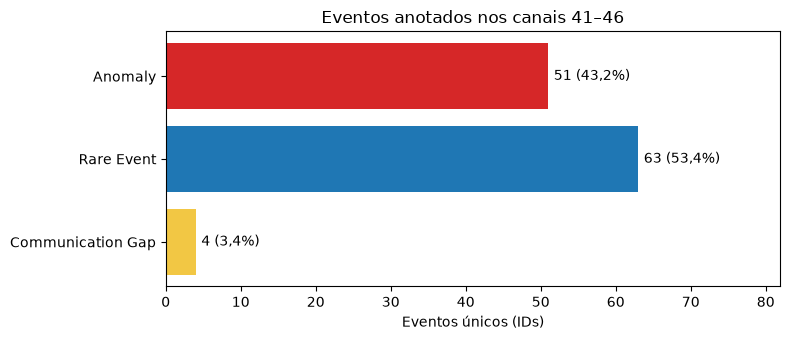

Total: 118 eventos únicos em 1255 intervalos anotados.


In [71]:
ordem_categorias = ["Anomaly", "Rare Event", "Communication Gap"]
cores_categorias = {
    "Anomaly": "#d62728",
    "Rare Event": "#1f77b4",
    "Communication Gap": "#f2c744",
}

contagem_eventos_categoria = eventos_unicos["Category"].value_counts()
categorias_extra = [
    categoria
    for categoria in contagem_eventos_categoria.index
    if categoria not in ordem_categorias
]
ordem_categorias.extend(categorias_extra)
contagem_eventos_categoria = contagem_eventos_categoria.reindex(
    ordem_categorias, fill_value=0
)

resumo_eventos = pd.DataFrame(
    {
        "Categoria": contagem_eventos_categoria.index,
        "Eventos únicos": contagem_eventos_categoria.values,
        "Percentual": (
            contagem_eventos_categoria.values
            / contagem_eventos_categoria.sum()
            * 100
        ).round(1),
    }
)
display(resumo_eventos)

fig, ax = plt.subplots(figsize=(8, 3.5))
bar_colors = [cores_categorias.get(c, "#777777") for c in resumo_eventos["Categoria"]]
bars = ax.barh(resumo_eventos["Categoria"], resumo_eventos["Eventos únicos"], color=bar_colors)
ax.invert_yaxis()
ax.set_xlabel("Eventos únicos (IDs)")
ax.set_title("Eventos anotados nos canais 41–46")

# MUDANÇA: o rótulo agora mostra o número e a porcentagem
rotulos = [
    f"{n} ({p:.1f}%)".replace(".", ",")
    for n, p in zip(resumo_eventos["Eventos únicos"], resumo_eventos["Percentual"])
]
ax.bar_label(bars, labels=rotulos, padding=4)
ax.set_xlim(0, max(resumo_eventos["Eventos únicos"].max() * 1.3, 1))
plt.tight_layout()
plt.show()

print(
    f"Total: {eventos_unicos['ID'].nunique()} eventos únicos "
    f"em {len(labels_clean)} intervalos anotados."
)

**Resposta.** Nos canais 41–46 há **118 eventos únicos**: 51 anomalias (43,2%), 63 eventos nominais raros (53,4%) e 4 lacunas de comunicação (3,4%). Esses eventos aparecem em 1.255 intervalos anotados porque um ID pode ter registros em vários canais e em vários trechos. As lacunas são uma categoria separada, não devem ser somadas a anomalias nem a eventos nominais raros ao responder perguntas específicas sobre essas duas classes.

**1.2 Qual é o intervalo de tempo entre o primeiro início e o último fim de cada anomalia ou evento nominal raro? Como os valores se comparam?**

> No primeiro gráfico, cada ponto é um evento (um ID). O eixo vertical mostra o tempo entre o primeiro início e o último fim, em **escala logarítmica**: cada marca é bem maior que a anterior (1 min, 10 min, 1 h, 6 h, 1 dia…). Os eventos em que o início é igual ao fim aparecem na faixa de baixo, "início = fim". O traço preto é a **mediana** de cada categoria, isto é, o valor do meio quando os eventos são colocados em ordem.
> O segundo gráfico resume os mesmos dados em faixas de tempo.
> Esse intervalo é calculado entre datas anotadas e não garante que o evento tenha permanecido ativo o tempo todo. O fim dos eventos também foi anotado com menos precisão do que o início.

,n,início = fim,mediana,1º quartil,3º quartil,mínimo,máximo
Category,,,,,,,
Anomaly,51,10,13 s,2 s,16 h 07 min,0 s,28 d 9 h
Rare Event,63,1,1 h 32 min,31 min,6 h 37 min,0 s,19 d 21 h


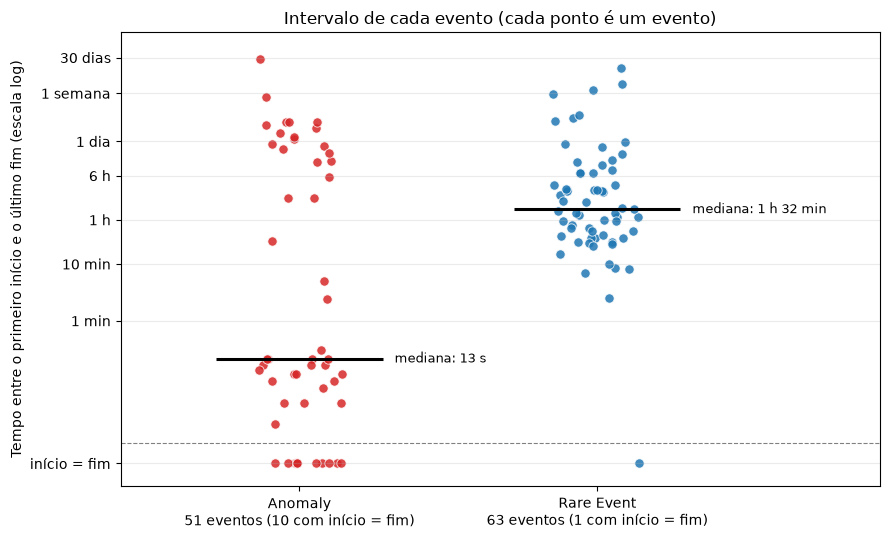

faixa,Menos de 1 min,1 min a 1 h,1 h a 1 dia,Mais de 1 dia
Category,,,,
Anomaly,29,3,9,10
Rare Event,1,23,32,7


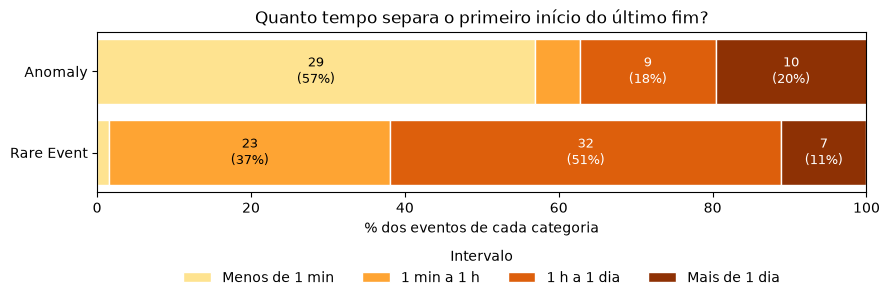

O intervalo é calculado entre datas anotadas e pode incluir trechos sem anotação.
A faixa 'Menos de 1 min' inclui os eventos com início = fim.


In [ ]:
categorias_duracao = ["Anomaly", "Rare Event"]
duracoes_eventos = eventos_unicos.loc[
    eventos_unicos["Category"].isin(categorias_duracao),
    ["ID", "Category", "intervalo_total"],
].copy()
duracoes_eventos["horas_entre_datas"] = (
    duracoes_eventos["intervalo_total"].dt.total_seconds() / 3600
)


def formatar_duracao(horas):
    """Escreve uma duração (dada em horas) em unidades fáceis de ler."""
    segundos = horas * 3600
    if segundos == 0:
        return "0 s"
    if segundos < 1:
        return "< 1 s"
    if segundos < 60:
        return f"{segundos:.0f} s"
    minutos_totais = int(round(segundos / 60))
    if minutos_totais < 60:
        return f"{minutos_totais} min"
    if horas < 24:
        h, m = divmod(minutos_totais, 60)
        return f"{h} h {m:02d} min"
    horas_totais = int(round(horas))
    d, h = divmod(horas_totais, 24)
    return f"{d} d {h} h"


# ---------- Tabela-resumo ----------
resumo_duracoes = (
    duracoes_eventos.groupby("Category")["horas_entre_datas"]
    .agg(
        n="count",
        n_zero=lambda valores: int((valores == 0).sum()),
        mediana_horas="median",
        q1_horas=lambda valores: valores.quantile(0.25),
        q3_horas=lambda valores: valores.quantile(0.75),
        minimo_horas="min",
        maximo_horas="max",
    )
    .reindex(categorias_duracao)
)

# MUDANÇA: a tabela mostra as durações em segundos/minutos/horas/dias,
# e não mais em horas arredondadas (que mostravam 0,00 para a mediana das anomalias).
resumo_legivel = resumo_duracoes.copy()
for coluna in ["mediana_horas", "q1_horas", "q3_horas", "minimo_horas", "maximo_horas"]:
    resumo_legivel[coluna] = resumo_legivel[coluna].map(formatar_duracao)
resumo_legivel.columns = ["n", "início = fim", "mediana", "1º quartil", "3º quartil", "mínimo", "máximo"]
display(resumo_legivel)

# ---------- Gráfico A: cada ponto é um evento ----------
menor_positivo = duracoes_eventos.loc[
    duracoes_eventos["horas_entre_datas"] > 0, "horas_entre_datas"
].min()
PISO = menor_positivo / 5          # posição desenhada para os eventos com início = fim
LINHA_SEPARADORA = menor_positivo / 2.2

fig, ax = plt.subplots(figsize=(9, 5.5))
rng_duracao = np.random.default_rng(42)
for posicao, categoria in enumerate(categorias_duracao, start=1):
    valores = duracoes_eventos.loc[
        duracoes_eventos["Category"] == categoria, "horas_entre_datas"
    ]
    y = valores.where(valores > 0, PISO)       # MUDANÇA: zeros ficam numa faixa própria
    jitter = rng_duracao.uniform(-0.15, 0.15, size=len(y))
    ax.scatter(
        posicao + jitter, y,
        color=cores_categorias[categoria],
        edgecolor="white", linewidth=0.6, alpha=0.85, s=45,
    )
    # MUDANÇA: traço preto = mediana de cada categoria
    mediana = valores.median()
    y_mediana = max(mediana, PISO)
    ax.hlines(y_mediana, posicao - 0.28, posicao + 0.28, color="black", linewidth=2.2)
    ax.text(
        posicao + 0.32, y_mediana, f"mediana: {formatar_duracao(mediana)}",
        va="center", fontsize=9,
    )

ax.axhline(LINHA_SEPARADORA, color="gray", linestyle="--", linewidth=0.8)
ax.set_yscale("log")
marcas = [PISO, 1/60, 10/60, 1, 6, 24, 168, 720]
nomes = ["início = fim", "1 min", "10 min", "1 h", "6 h", "1 dia", "1 semana", "30 dias"]
ax.set_yticks(marcas)
ax.set_yticklabels(nomes)
ax.minorticks_off()
ax.set_ylim(PISO / 2.5, 2000)
ax.set_xlim(0.4, 2.95)
ax.set_xticks([1, 2])
ax.set_xticklabels(
    [
        f"Anomaly\n{int(resumo_duracoes.loc['Anomaly', 'n'])} eventos "
        f"({int(resumo_duracoes.loc['Anomaly', 'n_zero'])} com início = fim)",
        f"Rare Event\n{int(resumo_duracoes.loc['Rare Event', 'n'])} eventos "
        f"({int(resumo_duracoes.loc['Rare Event', 'n_zero'])} com início = fim)",
    ]
)
ax.set_ylabel("Tempo entre o primeiro início e o último fim (escala log)")
ax.set_title("Intervalo de cada evento (cada ponto é um evento)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# ---------- Gráfico B: resumo por faixas (mais simples de ler) ----------
limites = [-0.1, 1 / 60, 1, 24, np.inf]    # em horas; -0,1 faz o zero entrar na 1ª faixa
rotulos_faixas = ["Menos de 1 min", "1 min a 1 h", "1 h a 1 dia", "Mais de 1 dia"]
duracoes_eventos["faixa"] = pd.cut(
    duracoes_eventos["horas_entre_datas"],
    bins=limites, labels=rotulos_faixas, right=False,
)
tabela_faixas = (
    pd.crosstab(duracoes_eventos["Category"], duracoes_eventos["faixa"])
    .reindex(index=categorias_duracao, columns=rotulos_faixas, fill_value=0)
)
percentuais = tabela_faixas.div(tabela_faixas.sum(axis=1), axis=0) * 100
display(tabela_faixas)

fig, ax = plt.subplots(figsize=(9, 3.4))
cores_faixas = plt.cm.YlOrBr(np.linspace(0.25, 0.9, len(rotulos_faixas)))
esquerda = np.zeros(len(categorias_duracao))
for i, faixa in enumerate(rotulos_faixas):
    larguras = percentuais[faixa].to_numpy()
    ax.barh(categorias_duracao, larguras, left=esquerda,
            color=cores_faixas[i], edgecolor="white", label=faixa)
    for j, (largura, inicio_barra) in enumerate(zip(larguras, esquerda)):
        if largura >= 6:
            n = int(tabela_faixas.iloc[j][faixa])
            ax.text(
                inicio_barra + largura / 2, j, f"{n}\n({largura:.0f}%)",
                ha="center", va="center", fontsize=9,
                color="white" if i >= 2 else "black",
            )
    esquerda += larguras
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% dos eventos de cada categoria")
ax.set_title("Quanto tempo separa o primeiro início do último fim?")
ax.legend(title="Intervalo", ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.28), frameon=False)
plt.tight_layout()
plt.show()

print("O intervalo é calculado entre datas anotadas e pode incluir trechos sem anotação.")
print("A faixa 'Menos de 1 min' inclui os eventos com início = fim.")

**Resposta.** Os intervalos variam muito, e as **anomalias se dividem em dois grupos**:

- **Anomalias muito curtas:** 29 das 51 anomalias têm intervalo menor que 1 minuto. Dessas, 10 têm início exatamente igual ao fim, e as demais duram poucos segundos. A mediana das anomalias é 13 segundos; ela **não é zero**, apenas pequena.
- **Anomalias longas:** as outras vão de alguns minutos até cerca de 28 dias (maior valor: 28 d 9 h). O 3º quartil das anomalias é 16 h 07 min.
- **Eventos nominais raros:** formam um grupo só. A mediana é 1 h 32 min, metade dos eventos fica entre 31 min e 6 h 37 min, e o maior intervalo é 19 d 21 h. Só 1 dos 63 tem início igual ao fim, e 23 têm intervalo menor que 1 minuto.

**Observação.** Intervalos muito curtos aparecem quase só em anomalias. Isso pode indicar que parte das anomalias é **pontual** (acontece em um instante, e a diferença de segundos vem do horário de cada canal), mas isso ainda precisa ser confirmado, por exemplo com a coluna `Length` de `anomaly_types.csv` (calculada para a missão inteira). Como são poucos eventos, trate como uma observação e não como regra.

**1.3 Existem eventos que afetam vários canais ao mesmo tempo (mesmo ID em múltiplos canais)? Com que frequência isso acontece?**

Category,Anomaly,Rare Event,Communication Gap
canais_afetados,,,
1,1,0,0
2,0,0,0
3,0,1,0
4,0,1,0
5,1,1,0
6,49,60,4


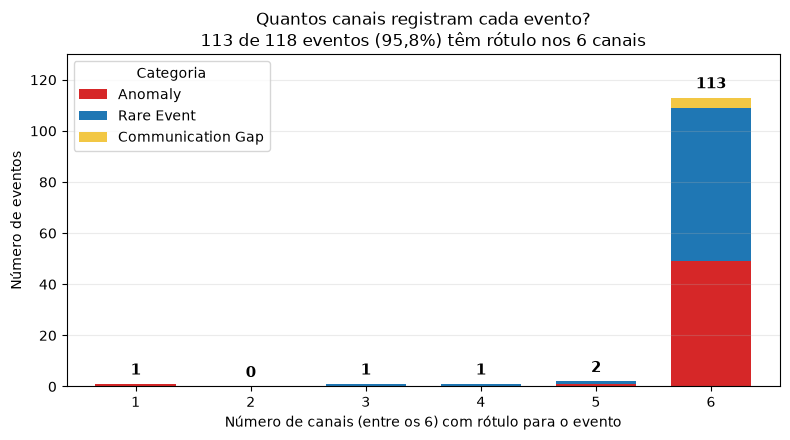

,ID,Category,canais_afetados
87,id_42,Anomaly,1
97,id_55,Rare Event,3
86,id_41,Rare Event,4
43,id_157,Anomaly,5
83,id_38,Rare Event,5


id_42 (Anomaly): sem rótulo em channel_42, channel_43, channel_44, channel_45, channel_46.
id_55 (Rare Event): sem rótulo em channel_42, channel_44, channel_46.
id_41 (Rare Event): sem rótulo em channel_43, channel_44.
id_157 (Anomaly): sem rótulo em channel_46.
id_38 (Rare Event): sem rótulo em channel_46.
Eventos com rótulo em mais de um canal: 117 de 118.
Eventos com rótulo nos seis canais: 113 de 118.
A tabela lista apenas eventos sem rótulo nos seis canais disponíveis.


In [73]:
ordem_eventos = (
    eventos_unicos.assign(
        numero_id=eventos_unicos["ID"].str.extract(r"(\d+)", expand=False).astype(int)
    )
    .sort_values(["Category", "numero_id"])
    ["ID"]
    .tolist()
)

# Cada par evento-canal é contado uma vez, mesmo que o canal tenha vários trechos.
eventos_canais = labels_clean[["ID", "Channel"]].drop_duplicates()
matriz_evento_canal = pd.crosstab(
    eventos_canais["ID"], eventos_canais["Channel"]
).reindex(index=ordem_eventos, columns=canais_disponiveis, fill_value=0)
matriz_evento_canal = matriz_evento_canal.gt(0)

resumo_canais_evento = eventos_unicos[["ID", "Category"]].copy()
resumo_canais_evento["canais_afetados"] = matriz_evento_canal.sum(axis=1).reindex(
    resumo_canais_evento["ID"]
).to_numpy()

distribuicao_canais = pd.crosstab(
    resumo_canais_evento["canais_afetados"], resumo_canais_evento["Category"]
).reindex(index=range(1, len(canais_disponiveis) + 1), fill_value=0)
distribuicao_canais = distribuicao_canais.reindex(columns=ordem_categorias, fill_value=0)
display(distribuicao_canais)

n_multicanal = int((resumo_canais_evento["canais_afetados"] > 1).sum())
n_todos_canais = int((resumo_canais_evento["canais_afetados"] == len(canais_disponiveis)).sum())
pct_todos = n_todos_canais / len(eventos_unicos) * 100

# MUDANÇAS: barras empilhadas (em vez de lado a lado), número escrito em cima de
# TODAS as barras (inclusive as de valor 1) e o resumo principal no subtítulo.
fig, ax = plt.subplots(figsize=(8, 4.5))
distribuicao_canais.plot(
    kind="bar", stacked=True, ax=ax, width=0.7,
    color=[cores_categorias.get(c, "#777777") for c in distribuicao_canais.columns],
)
totais = distribuicao_canais.sum(axis=1)
for posicao, total in enumerate(totais):
    ax.text(posicao, total + totais.max() * 0.02, str(int(total)),
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_ylim(0, totais.max() * 1.15)
ax.set_xlabel("Número de canais (entre os 6) com rótulo para o evento")
ax.set_ylabel("Número de eventos")
ax.set_title(
    "Quantos canais registram cada evento?\n"
    f"{n_todos_canais} de {len(eventos_unicos)} eventos "
    f"({pct_todos:.1f}%) têm rótulo nos 6 canais".replace(".", ","),
)
ax.legend(title="Categoria", loc="upper left")
ax.set_xticklabels(distribuicao_canais.index, rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

canais_por_id = eventos_canais.groupby("ID")["Channel"].agg(list)
eventos_incompletos = resumo_canais_evento.loc[
    resumo_canais_evento["canais_afetados"] < len(canais_disponiveis)
].copy()
eventos_incompletos = eventos_incompletos.sort_values(["canais_afetados", "Category", "ID"])
display(eventos_incompletos)

for _, linha in eventos_incompletos.iterrows():
    canais_sem_rotulo = [
        canal for canal in canais_disponiveis if canal not in canais_por_id[linha["ID"]]
    ]
    print(
        f"{linha['ID']} ({linha['Category']}): sem rótulo em "
        f"{', '.join(canais_sem_rotulo)}."
    )

print(f"Eventos com rótulo em mais de um canal: {n_multicanal} de {len(eventos_unicos)}.")
print(f"Eventos com rótulo nos seis canais: {n_todos_canais} de {len(eventos_unicos)}.")
print("A tabela lista apenas eventos sem rótulo nos seis canais disponíveis.")

**Resposta.** Quase todos os eventos são multicanal: **117 de 118** aparecem em mais de um canal, e **113 (95,8%)** aparecem nos seis. Os 5 casos restantes são: 1 anomalia em um canal, 1 evento raro em três canais, 1 evento raro em quatro e 2 eventos em cinco (um raro e uma anomalia). Isso sugere que os rótulos deste recorte são majoritariamente compartilhados entre os canais, mas não prova que os sinais mudem exatamente ao mesmo tempo; a comparação dos horários de início será feita na pergunta 2.2.

Dois desses casos, `id_55` e `id_157`, estão entre os eventos que o artigo do ESA-ADB (Kotowski et al., 2024) cita como difíceis de ver usando apenas os canais 41–46. "Sem rótulo" significa que não há anotação para aquele ID naquele canal, e não necessariamente que o sinal não mudou.

**1.4 Há concentração de eventos em algum período da linha do tempo anonimizada (2000–2013), ou as ocorrências parecem distribuídas ao longo do recorte?**

Category,Anomaly,Rare Event,Communication Gap
ano_anotado,,,
2000,5,5,0
2001,0,7,3
2002,4,1,1
2003,3,3,0
2004,2,4,0
2005,4,5,0
2006,4,2,0
2007,5,8,0
2008,3,4,0


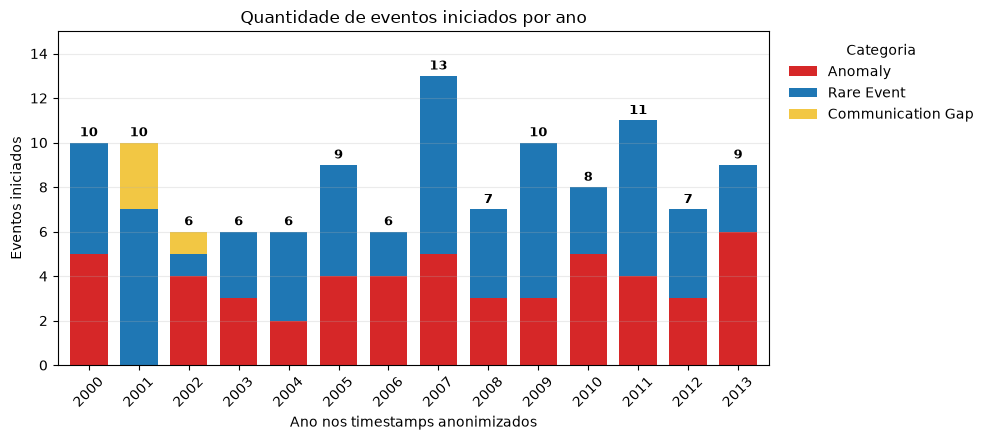

Maior contagem anual: 13 eventos, no(s) ano(s) anotado(s) [2007].
Divisão treino/teste (aproximada): 2006-12-31
Eventos que começam antes: 53 | depois: 65


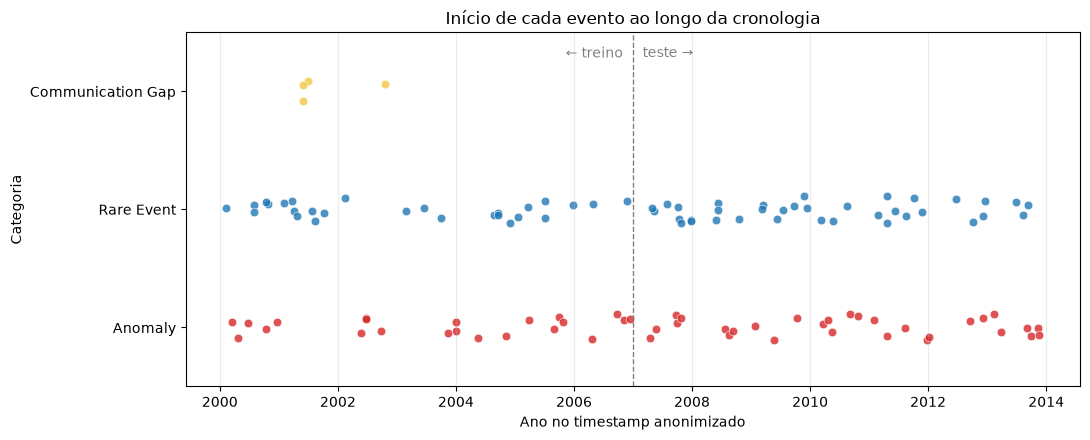

Cada ponto representa o início de um ID; a posição vertical é levemente deslocada apenas para separar pontos próximos. As datas são anonimizadas e não representam o calendário real da missão.


,ID,inicio_utc,fim_utc,intervalo_total
94,id_52,2001-05-27 18:45:58.296000+00:00,2001-05-28 14:30:28.296000+00:00,0 days 19:44:30
95,id_53,2001-06-27 08:13:55.296000+00:00,2001-06-27 09:02:25.296000+00:00,0 days 00:48:30
96,id_54,2002-10-16 05:59:55.242000+00:00,2002-10-16 11:54:25.242000+00:00,0 days 05:54:30
98,id_57,2001-05-30 22:24:28.296000+00:00,2001-05-31 11:27:58.296000+00:00,0 days 13:03:30


In [75]:
eventos_tempo = eventos_unicos.dropna(subset=["inicio_utc"]).copy()
eventos_tempo["ano_anotado"] = eventos_tempo["inicio_utc"].dt.year
# Para os gráficos de data, usamos o horário sem fuso (evita incompatibilidade com a série).
eventos_tempo["inicio_plot"] = eventos_tempo["inicio_utc"].dt.tz_localize(None)

contagem_anual = pd.crosstab(
    eventos_tempo["ano_anotado"], eventos_tempo["Category"]
).reindex(columns=ordem_categorias, fill_value=0)
anos_completos = range(
    int(eventos_tempo["ano_anotado"].min()),
    int(eventos_tempo["ano_anotado"].max()) + 1,
)
contagem_anual = contagem_anual.reindex(anos_completos, fill_value=0)
display(contagem_anual)

total_por_ano = contagem_anual.sum(axis=1)

# ---------- Gráfico A: eventos por ano ----------
fig, ax = plt.subplots(figsize=(10, 4.5))
contagem_anual.plot(
    kind="bar", stacked=True, ax=ax, width=0.75,
    color=[cores_categorias.get(c, "#777777") for c in contagem_anual.columns],
)
# MUDANÇA: total escrito em cima de cada barra
for posicao, total in enumerate(total_por_ano):
    ax.text(posicao, total + 0.15, str(int(total)),
            ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_ylim(0, total_por_ano.max() + 2)        # MUDANÇA: espaço acima da maior barra
ax.set_xlabel("Ano nos timestamps anonimizados")
ax.set_ylabel("Eventos iniciados")
ax.set_title("Quantidade de eventos iniciados por ano")
# MUDANÇA: legenda fora do gráfico, para não cobrir as barras
ax.legend(title="Categoria", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

max_eventos_ano = int(total_por_ano.max())
anos_pico = total_por_ano.index[total_por_ano == max_eventos_ano].tolist()
print(f"Maior contagem anual: {max_eventos_ano} eventos, no(s) ano(s) anotado(s) {anos_pico}.")

# ---------- Gráfico B: início de cada evento na linha do tempo ----------
# MUDANÇA: linha vertical na divisão treino/teste. O artigo usa a primeira metade
# do período para treino; aqui a divisão é o ponto médio da série do channel_41.
data_corte = ch41.index.min() + (ch41.index.max() - ch41.index.min()) / 2
# convertemos a data de corte para o mesmo formato antes de comparar.
if data_corte.tzinfo is not None:
    data_corte = data_corte.tz_convert("UTC").tz_localize(None)
antes = int((eventos_tempo["inicio_plot"] < data_corte).sum())
depois = int((eventos_tempo["inicio_plot"] >= data_corte).sum())
print(f"Divisão treino/teste (aproximada): {data_corte.date()}")
print(f"Eventos que começam antes: {antes} | depois: {depois}")

fig, ax = plt.subplots(figsize=(11, 4.5))
rng_tempo = np.random.default_rng(42)
for posicao, categoria in enumerate(ordem_categorias):
    datas_inicio = eventos_tempo.loc[eventos_tempo["Category"] == categoria, "inicio_plot"]
    deslocamento_vertical = rng_tempo.uniform(-0.12, 0.12, size=len(datas_inicio))
    ax.scatter(
        datas_inicio, posicao + deslocamento_vertical,
        color=cores_categorias.get(categoria, "#777777"),
        s=38, alpha=0.8, edgecolor="white", linewidth=0.5,
    )

ax.axvline(data_corte, color="gray", linestyle="--", linewidth=1)
ax.text(data_corte - pd.Timedelta(days=60), 0.96, "← treino", ha="right", va="top",
        transform=ax.get_xaxis_transform(), color="gray", fontsize=10)
ax.text(data_corte + pd.Timedelta(days=60), 0.96, "teste →", ha="left", va="top",
        transform=ax.get_xaxis_transform(), color="gray", fontsize=10)

ax.set_yticks(range(len(ordem_categorias)), ordem_categorias)
ax.set_ylim(-0.5, len(ordem_categorias) - 0.5)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Ano no timestamp anonimizado")
ax.set_ylabel("Categoria")
ax.set_title("Início de cada evento ao longo da cronologia")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "Cada ponto representa o início de um ID; a posição vertical é levemente deslocada "
    "apenas para separar pontos próximos. As datas são anonimizadas e não representam "
    "o calendário real da missão."
)

# ---------- Conferência: datas das lacunas de comunicação ----------
display(
    eventos_unicos.loc[
        eventos_unicos["Category"] == "Communication Gap",
        ["ID", "inicio_utc", "fim_utc", "intervalo_total"],
    ]
)

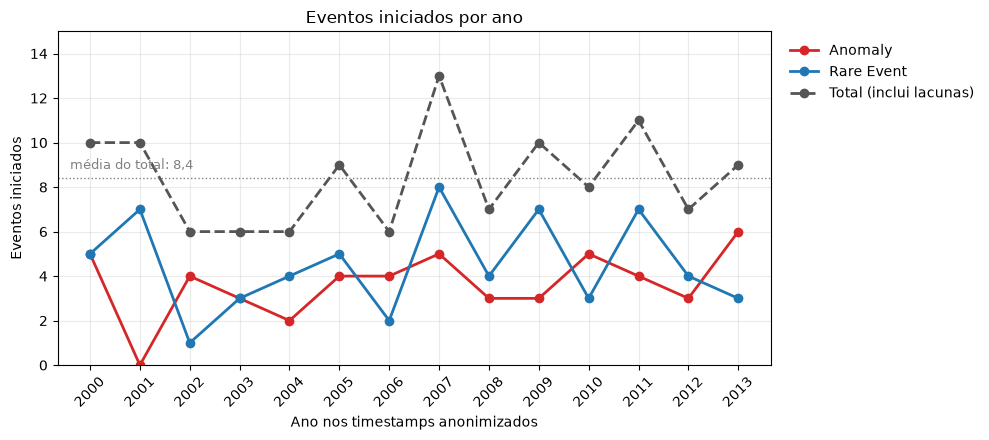

As 4 lacunas de comunicação não têm linha própria (quase todos os anos têm 0), mas estão somadas no total.


In [76]:
fig, ax = plt.subplots(figsize=(10, 4.5))
anos = contagem_anual.index

for categoria in ["Anomaly", "Rare Event"]:
    ax.plot(anos, contagem_anual[categoria], marker="o", linewidth=2,
            color=cores_categorias[categoria], label=categoria)
ax.plot(anos, total_por_ano, marker="o", linewidth=2, linestyle="--",
        color="#555555", label="Total (inclui lacunas)")

# Linha pontilhada = média anual do total: mostra quais anos ficam acima ou abaixo do normal
media_total = total_por_ano.mean()
ax.axhline(media_total, color="gray", linestyle=":", linewidth=1)
ax.text(anos.min() - 0.4, media_total + 0.25,
        f"média do total: {media_total:.1f}".replace(".", ","),
        fontsize=9, color="gray", va="bottom")

ax.set_xticks(list(anos))
ax.set_xticklabels(anos, rotation=45)
ax.set_ylim(0, total_por_ano.max() + 2)
ax.set_xlabel("Ano nos timestamps anonimizados")
ax.set_ylabel("Eventos iniciados")
ax.set_title("Eventos iniciados por ano")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
print("As 4 lacunas de comunicação não têm linha própria (quase todos os anos têm 0), mas estão somadas no total.")

**Resposta.** Não há um período que concentre os eventos. Os 118 eventos começam em todos os anos de 2000 a 2013, com média de **8,4 eventos por ano** (mediana 8,5). A contagem anual varia de 6 a 13, e 12 dos 14 anos ficam entre 6 e 10 eventos.

**O que os gráficos mostram**

- **Total por ano:** o maior valor é 2007, com 13 eventos (11% do total), seguido de 2011, com 11. O menor valor, 6 eventos, ocorre em 2002, 2003, 2004 e 2006.
- **Anomalias:** são regulares. Ficam entre 2 e 6 por ano, com uma exceção: 2001 não tem nenhuma. No gráfico de pontos, não aparecem anomalias entre o final de 2000 e meados de 2002.
- **Eventos raros:** variam mais, de 1 (em 2002) a 8 (em 2007) por ano. O pico de 2007 vem principalmente deles: são 8 eventos raros e 5 anomalias.
- **Lacunas de comunicação:** são 4, três em 2001 e uma em 2002. Todas estão na primeira metade do período.
- **Gráfico de linhas:** confirma que as anomalias oscilam pouco e os eventos raros oscilam mais. Os zigue-zagues entre um ano e outro mostram variação de ano para ano e não devem ser lidos como tendência de aumento ou queda.

**Antes e depois da divisão treino/teste.** Dividindo o período ao meio (cerca de 2006-12-31, o ponto médio da série), 53 eventos começam na primeira metade (44,9%) e 65 na segunda (55,1%).

| Período | Anomalias | Eventos raros | Lacunas | Total |
|---|---|---|---|---|
| 2000–2006 | 22 | 27 | 4 | 53 |
| 2007–2013 | 29 | 36 | 0 | 65 |

As duas metades têm anomalias e eventos raros, em quantidades parecidas.

**Conferência das lacunas de comunicação.** As três lacunas de 2001 ocorrem nas mesmas datas em que o artigo do ESA-ADB (Kotowski et al., 2024) descreve mudanças bruscas na frequência de amostragem dos canais 41–46:

| Evento | Início → fim da lacuna | Data citada no artigo |
|---|---|---|
| `id_52` | 2001-05-27 → 2001-05-28 | 2001-05-28 |
| `id_57` | 2001-05-30 → 2001-05-31 | 2001-05-31 |
| `id_53` | 2001-06-27 (48 min) | 2001-06-27 |

A quarta lacuna (`id_54`, 2002-10-16, cerca de 6 h) não tem relação com essas datas. A coincidência sugere que as lacunas rotuladas em 2001 estejam ligadas a essas mudanças de amostragem, mas isso **não está confirmado**: o artigo afirma que esses episódios não foram anotados, e aqui eles aparecem como `Communication Gap`. Essa diferença será verificada na pergunta 2.4, olhando o intervalo entre leituras nessas datas.

**Como interpretar com cuidado**

- A análise é descritiva: compara contagens anuais, sem teste estatístico. Como referência simples, se os eventos fossem sorteados ao acaso entre os anos, a variação típica em torno da média seria de cerca de 2,9 eventos por ano. A variação observada é de 2,2, ou seja, não é maior do que o esperado ao acaso.
- A contagem por ano é um nível grosseiro. Ela não mostra se há eventos agrupados em semanas ou meses dentro de um mesmo ano.
- O gráfico mostra **quando os eventos foram anotados**, e não necessariamente quando mais ocorreram. Mais anotações em um período podem refletir mais eventos ou mais atenção na revisão.
- As datas são anonimizadas: os gráficos mostram a ordem e a distribuição relativa, não o calendário real da missão.

**Conclusão para a pesquisa.** Os eventos estão distribuídos ao longo de todo o período, e as duas metades têm anomalias e eventos raros. As análises seguintes, portanto, não ficam restritas a uma fase específica.

#### 2. Comportamento dos canais durante eventos

**2.1 Como o valor do channel_41 se comporta durante uma anomalia anotada comparado com um período normal? O desvio é óbvio visualmente?**

**2.2 O mesmo evento aparece nos canais 41–46 ao mesmo tempo ou cada canal reage de forma diferente (em tempos diferentes)?**

**2.3 Existem períodos onde o sensor fica com o mesmo valor por muito tempo (valor "congelado")? Isso pode ser dado ruim, travamento ou sensor em modo de espera?**

**2.4 Qual é o intervalo típico entre leituras (frequência de amostragem)? Existem lacunas grandes - períodos sem nenhuma leitura?**

#### 3. Telecomandos e contexto operacinal

**3.1 Quantos telecomandos diferentes foram executados ao longo dos 14 anos? Quais são os mais frequentes?**

**3.2 Existe algum telecomando que aparece frequentemente nas horas ou dias que antecedem eventos nominais raros nos canais 41–46?**

**3.3 Esse mesmo telecomando também aparece antes de anomalias reais?**

**3.4 Qual é a prioridade dos telecomandos que aparecem próximos aos eventos? Comandos de prioridade 3 são mais associados a eventos do que comandos de prioridade 1?**

#### 4. Qualidade dos Dados

**4.1 Em que proporção do tempo os canais têm dados válidos? Existe algum canal com muito mais lacunas que os outros?**

**4.2 Durante as anomalias anotadas, os dados estavam completos ou havia lacunas/congelamentos que poderiam ter causado o alerta?**

**4.3 Existem valores extremos (muito acima ou abaixo do padrão histórico) que ocorrem fora de qualquer evento anotado? O que isso significa?**

#### 5. Detecção de Anomalias com Limites

**5.1 Se usarmos uma regra simples ("alerta quando o valor sai de 3 desvios padrões da mediana"), quantos alertas seriam gerados? Quantos coincidiriam com anomalias reais? Quantos seriam eventos nominais raros?**

**5.2 Um detector simples conseguiria distinguir os 118 eventos da Mission1 apenas pelo score numérico, sem contexto?**